# Choosing MEMAR hyperparameters over a validation set from GLORI experiments in HEK293T cells

### Import packages

In [1]:
#Packages needed for the notebook
using CSV 
using Serialization 
using Revise 
using LinearAlgebra 
using ReverseDiff
using PyPlot
using Statistics 
using NaNStatistics 
using Random 

### Including Files

In [2]:
function correct_path(splitted_path, String)
    """Function to retrieve files in a given path.
    It takes as input:
        1) splitted path: the current path split by each separator
        2) String: the path to reach the wanted file 
    The function returns:
        1) the correct complete path to reach the file
    """
    S="" #String initialization
    for i in 1:(length(splitted_path)-1)
        #Constructing the path with the correct separator and removing the last term
        S=S*splitted_path[i]*"/" 
    end
    #Final Output
    return S*String 
end

correct_path (generic function with 1 method)

In [3]:
#Including files with the functions
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets

### Datasets

In [4]:
#Importing, training, validation and prior datasets
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
validation=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Validation_GLORI.bin")) 
prior_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_GLORI.bin")); 

In [5]:
#Saving all gene labels for the three datasets
gene_train=keys(train);
gene_valid=keys(validation);
gene_prior=keys(prior_HEK);

In [6]:
#Creating all train sets over transcripts
train_met, ratio_train , gene_train_met, train_not , gene_train_not =crete_set_all(train, gene_train);

### Constant prior

$$p_0(m)=\frac{1}{\mathcal{N}_\mathcal{T}}\sum_{i=1}^{\mathcal{N}_\mathcal{T}} \frac{N^{T'_i}_{m^6A}}{N^{T'_i}_{m^6A}+N^{T'_i}_A}=\langle p_0^{T'}(m)\rangle_{T'}$$

In [7]:
Ava=[]
[push!(Ava, train[a].perc_met) for a in gene_train];
Ava=mean(Ava)

constant_prior=deepcopy(validation)
[constant_prior[a].perc_met=Ava for a in keys(validation)];

### Showing AUPRCs over different set of hypeparameters

Two hypeparameters are used, one related to the tolerance to stop the gradient computation, and the second related to the strength of the L2-regularization parameter to better control over-fitting.

In [8]:
Indexes=shuffle!(vcat(1:length(train_not)))[1:2000000]
serialize(correct_path(split(pwd(), '/'), "Mapping/Data/Index_train_not.bin"),Indexes);

In [20]:
A=AUPRC_hyperparams(train_met,  ratio_train, train_not, Indexes, constant_prior, validation; pas=0.005);

Converged at iteration 140, where the maximum error is 0.0009986091315934789
Converged at iteration 50, where the maximum error is 0.0009349334643058097
Converged at iteration 69, where the maximum error is 0.0009792358256550586
Converged at iteration 51, where the maximum error is 0.0007783048260653139
Converged at iteration 53, where the maximum error is 0.0009175130605247679
Converged at iteration 49, where the maximum error is 0.0008825780999241369
Converged at iteration 59, where the maximum error is 0.000970356848475505
Converged at iteration 54, where the maximum error is 0.0009957794228930813
Converged at iteration 859, where the maximum error is 9.995996636666613e-5
Converged at iteration 286, where the maximum error is 9.957144266390348e-5
Converged at iteration 142, where the maximum error is 9.782583320500614e-5
Converged at iteration 92, where the maximum error is 9.834804927973551e-5
Converged at iteration 74, where the maximum error is 7.002793454381111e-5
Converged at i

Plotting results:

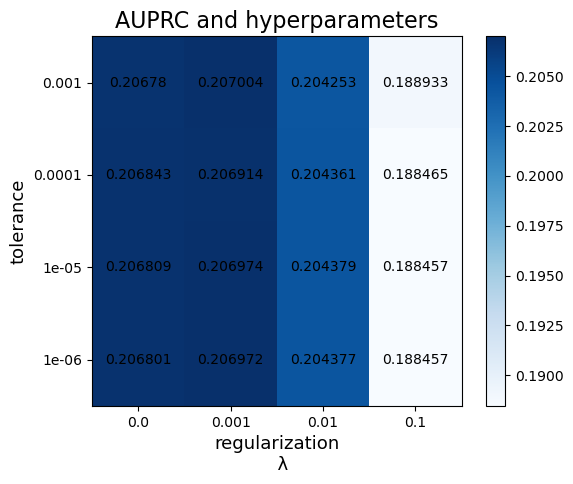

In [21]:
close("all")
imshow(A, cmap="Blues", vmin=minimum(vcat(A...)), vmax=maximum(vcat(A...)))
[[text(j-1, i-1, round(A[i][j], digits=6), ha="center", va="center", color="black") for j in 1:4] for i in 1:4]
colorbar()
xticks([0, 1, 2, 3], [0, 0.001, 0.01, 0.1])
yticks([0, 1, 2, 3],[0.001, 0.0001, 0.00001, 0.000001])
xlabel("regularization\n  λ", size=13)
ylabel("tolerance", size=13)
title("AUPRC and hyperparameters", size=16)
gcf()

### Training MEMAR over GLORI-seq with chosen hypeparameters

In [9]:
#Indexes=shuffle!(vcat(1:length(train_not)))[1:2000000]
#serialize(correct_path(split(pwd(), '/'), "Mapping/Data/Index_train_not.bin"),Indexes);
Indexes=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Index_train_not.bin"));

In [ ]:
#Training the methylated dataset
M5=strucutre_model(train_met , ratio_train ; Lseq=8, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001)
#Training the non-methylated dataset
M6=strucutre_model(train_not[Indexes], vcat(ones(1,length(Indexes))...); Lseq=8, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001);  

i) We can save the models trained removing the comments in the code here below:

In [ ]:
#Saving models
#serialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin"), M5)
#serialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin"),M6)

ii) alternatively, models already trained, to reproduce the same results as in the paper figures, can be used from already deposited files in the "/Data" folder

### Distibution of motives (train-set):

In [32]:
#Computing the distribution of methylated sites
bin=collect(0:0.001:1);
avarege_window=20
x_met, y_met=avarege_distribution(train, gene_train, avarege_window, bin; label=1)
x_not, y_not=avarege_distribution(train, gene_train, avarege_window, bin; label=0);

### Mapping:

In [33]:
#Projecting position of transcripts into a sequence made of 1/3 of 5'UTR, 1/3 CDS and 1/3 3'UTR 
MAP=mapping_position(validation, intersect(gene_valid, vcat(keys(prior_HEK)...)));

### Transcript-dependent prior

In [34]:
P=[]
[push!(P, prior_HEK[a].perc_met) for a in keys(prior_HEK)]
[prior_HEK[a].perc_met=Ava/mean(P).*prior_HEK[a].perc_met for a in keys(prior_HEK)];

### Computing predictions over adenosines in validation set

#### MEMAR-XT: Modulated distant with transcript-dependent prior

$$p(1|\vec{s}, x, T) \propto p(\vec{s}_T,|1)\cdot d(x|1 )
 \cdot p_0^T(1)$$

In [ ]:
score_met,score_not=score_ps_ds_pm(M5, M6, validation,keys(MAP), prior_HEK ; verb=true, map=MAP, d_met=[x_met, y_met], d_not=[x_not, y_not]);

### Choosing Treshold

In [36]:
#Computing Precision Recall Curve, and the F1 score. Then, saving the threshold value which maximize the F1 score.
_,tresh=plot_PR_score(vcat(score_met...), vcat(score_not...),  "goldenrod",L"p(\vec{s}_T|m)\cdot d(x(\vec{s}_T|m)\cdot p_0^T(m)"; xx=-0.02, pas=0.005,ls="-", mark="o");
print("Threshold value that maximize F1 score: $tresh")

Threshold value that maximize F1 score: 0.225